# Week 5 - Wed Lab (09/30/26) 

This code accompanies activities for the 09/30/26 lab.

**Table of Contents**

1. [Plicker Questions Code](#sec1)
2. [Cosine Similarity Whiteboard Activity - Your Task](#sec2)
3. [Wikipedia country-specific data](#sec3)

<a id="sec1"></a>
## 1. Plicker Questions Code

This code relates to the Question 13 on the Plicker set of questions for today. We will run the code line by line to see what is going on.

In [22]:
from datetime import datetime, timedelta

**Create a new datetime object**

In [23]:
date1 = datetime(2023, 5, 1)
type(date1)

datetime.datetime

**Create a new timedelta object**

In [24]:
delta = timedelta(days=10)
type(delta)

datetime.timedelta

In [25]:
print(delta)

10 days, 0:00:00


**Adding the two objects**

In [26]:
date2 = date1 + delta
print(date2)

2023-05-11 00:00:00


**Why is this possible?**

Let's show all methods / properties of the object:

In [27]:
dir(date1)

['__add__',
 '__class__',
 '__delattr__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__ne__',
 '__new__',
 '__radd__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__rsub__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 'astimezone',
 'combine',
 'ctime',
 'date',
 'day',
 'dst',
 'fold',
 'fromisocalendar',
 'fromisoformat',
 'fromordinal',
 'fromtimestamp',
 'hour',
 'isocalendar',
 'isoformat',
 'isoweekday',
 'max',
 'microsecond',
 'min',
 'minute',
 'month',
 'now',
 'replace',
 'resolution',
 'second',
 'strftime',
 'strptime',
 'time',
 'timestamp',
 'timetuple',
 'timetz',
 'today',
 'toordinal',
 'tzinfo',
 'tzname',
 'utcfromtimestamp',
 'utcnow',
 'utcoffset',
 'utctimetuple',
 'weekday',
 'year']

Let's look up the docstring of the method `__add__`, which is what is called when we use the + operator:

In [28]:
help(date1.__add__)

Help on method-wrapper:

__add__ = <method-wrapper '__add__' of datetime.datetime object>
    Return self+value.



**Conclusion:** There is a class method that will accept any value type and then act accordingly to figure out how to add that value to the date, if possible.

<a id="sec2"></a>
## 2. Cosine Similarity Whiteboard Activity

This activity was completed by hand, here is how to do it via Python code.

### Inputs for the problem

In [29]:
documents = [
    "Max likes Sam.",    # D1
    "Sam likes Max.",    # D2
    "Max and Sam.",      # D3
    "Winter likes fall." # D4
]

query = "Sam likes winter"

### Step 1: Create vocabulary of all terms

First I will concatenate all strings into one.

In [30]:
allText = " ".join(documents + [query])
print(allText)

Max likes Sam. Sam likes Max. Max and Sam. Winter likes fall. Sam likes winter


I don't want to have punctuation. There are several ways to do that. Let's see some:

#### Method 1: Iterate over the string, leave out punctuations

In [31]:
import string
print(string.punctuation)


!"#$%&'()*+,-./:;<=>?@[\]^_`{|}~


In [32]:
allText_noPunct = "".join([ch for ch in allText if not ch in string.punctuation])
print(allText_noPunct)

Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter


### Method 2: Use built-in methods

Pythyn's built-in `str` class has many useful methods for translating a set of characters to another one. Let's see the method in action:

In [33]:
allText.translate(str.maketrans("", "", string.punctuation))

'Max likes Sam Sam likes Max Max and Sam Winter likes fall Sam likes winter'

What's going on?

In [34]:
print(str.maketrans("", "", string.punctuation))

{33: None, 34: None, 35: None, 36: None, 37: None, 38: None, 39: None, 40: None, 41: None, 42: None, 43: None, 44: None, 45: None, 46: None, 47: None, 58: None, 59: None, 60: None, 61: None, 62: None, 63: None, 64: None, 91: None, 92: None, 93: None, 94: None, 95: None, 96: None, 123: None, 124: None, 125: None, 126: None}


We can see that all ASCII Characters from 0-32 and from 65 to 90 are missing, because those characters will be deleted.

Here is what is happening:

```
str.maketrans(from_str, to_str, delete_chars)
#              ^          ^        ^
#           1st arg    2nd arg  3rd arg
```

* 1st argument (""): The characters you want to replace. (Empty string = replace nothing)

* 2nd argument (""): The characters to replace them with. (Empty string = no replacement mapping)

* 3rd argument (string.punctuation): The characters you want to delete entirely.

### Our vocabulary

Here is a Python one-liner that takes our variable `allText_noPunct` and find the unique words in it.

In [35]:
words = set(allText_noPunct.lower().split())
words

{'and', 'fall', 'likes', 'max', 'sam', 'winter'}

In [36]:
voc = sorted(words)
voc

['and', 'fall', 'likes', 'max', 'sam', 'winter']

### YOUR TURN

Write code to implement the other steps of the process shown in Slide 7.

**Show your process before writing any functions.**

**Use markdown to label the three remaining steps.**

### Represent each document and the query in the vector space created by these terms

In [37]:
def get_words(text):
    text_clean = text.translate(str.maketrans("", "", string.punctuation))
    return text_clean.lower().split()

doc_vecs = []
for doc in documents:
    words = get_words(doc)
    vec = [words.count(w) for w in voc]
    doc_vecs.append(vec)

query_words = get_words(query)
query_vec = [query_words.count(w) for w in voc]

print("Voc:", voc)
for i, v in enumerate(doc_vecs):
    print(f"D{i+1}:", v)
print("Query:", query_vec)

Voc: ['and', 'fall', 'likes', 'max', 'sam', 'winter']
D1: [0, 0, 1, 1, 1, 0]
D2: [0, 0, 1, 1, 1, 0]
D3: [1, 0, 0, 1, 1, 0]
D4: [0, 1, 1, 0, 0, 1]
Query: [0, 0, 1, 0, 1, 1]


### Calculate the cosine similarity between the query and each document

In [38]:
import math

def dot(v1, v2):
    return sum(a * b for a, b in zip(v1, v2))

def norm(v):
    return math.sqrt(sum(a**2 for a in v))

sims = []
q_norm = norm(query_vec)

for i, d_vec in enumerate(doc_vecs):
    d_norm = norm(d_vec)
    if d_norm == 0 or q_norm == 0:
        score = 0.0
    else:
        score = dot(d_vec, query_vec) / (d_norm * q_norm)
    sims.append(score)
    print(f"D{i+1} similarity: {score:.4f}")

D1 similarity: 0.6667
D2 similarity: 0.6667
D3 similarity: 0.3333
D4 similarity: 0.6667


### Rank the results based on the cosine similarity

In [39]:
results = []
for i in range(len(documents)):
    results.append((f"D{i+1}", sims[i]))

results.sort(key=lambda x: x[1], reverse=True)

print("Ranked Results:")
for rank, (doc_id, score) in enumerate(results, 1):
    print(f"{rank}. {doc_id} - Score: {score:.4f}")

Ranked Results:
1. D1 - Score: 0.6667
2. D2 - Score: 0.6667
3. D4 - Score: 0.6667
4. D3 - Score: 0.3333


<a id="sec3"></a>
## 3. Wikipedia Country-Specific Data

If we know the URL of a date, for example:

```
https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv
```

we can use pandas to read the content of the file into a dataframe. 

In [40]:
import pandas as pd

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

df = pd.read_csv(url, sep='\t')

df.head()

HTTPError: HTTP Error 403: Forbidden

Why did this happen? Wikimedia didn't like that we didn't identify ourselves. This is why we need to first get data with requests, then read it from pandas.

In [41]:
import pandas as pd
import requests, io

url = "https://analytics.wikimedia.org/published/datasets/country_project_page/2026-09-29.tsv"

headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: wendywellesley@gmail.com)'}
response = requests.get(url, headers=headers)

df = pd.read_csv(io.StringIO(response.text), sep='\t')
df.head()

,Algeria,DZ,ar.wikipedia,3947,Ø°ÙØ§Ø¡_Ø§ØµØ·ÙØ§Ø¹Ù,Q11660,122
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


The dataframe doesn't have column name. 

**Your task:** Read the README file to find out the column names and add them to the dataframe.


In [42]:
url = "https://analytics.wikimedia.org/published/datasets/country_project_page/00_README.html"
res = requests.get(url, headers=headers)

cols = ['country', 'country_code', 'project', 'page_views', 'page_title', 'wikidata_id', 'page_id']

df.columns = cols
df.head()

,country,country_code,project,page_views,page_title,wikidata_id,page_id
0,Argentina,AR,es.wikipedia,3094323,Juana_Viale,Q9016209,115
1,Argentina,AR,es.wikipedia,327209,JosÃ©_Mourinho,Q79983,114
2,Argentina,AR,es.wikipedia,4449701,Copa_Libertadores,Q184795,386
3,Argentina,AR,es.wikipedia,47340,Thomas_Sankara,Q202155,119
4,Argentina,AR,es.wikipedia,5640452,Michael_Jackson,Q2831,177


# Task 3: Combining datasets to answer RQs

In [43]:
import pandas as pd
import requests
import io
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

### Store name of the shows, Wikipedia page titles, and MyDramaList ratings

In [44]:
shows_data = [
    {"title": "When Life Gives You Tangerines", "page_title": "When_Life_Gives_You_Tangerines", "rating": 9.3},
    {"title": "Reply 1988", "page_title": "Reply_1988", "rating": 9.0},
    {"title": "Crash Landing on You", "page_title": "Crash_Landing_on_You", "rating": 9.0},
    {"title": "Reset", "page_title": "Reset_(Chinese_TV_series)", "rating": 9.0},
    {"title": "The Glory", "page_title": "The_Glory_(TV_series)", "rating": 8.9},
    {"title": "Love in the Clouds", "page_title": "Love_in_the_Clouds", "rating": 8.8},
    {"title": "Someday or One Day", "page_title": "Someday_or_One_Day", "rating": 8.8},
    {"title": "The Story of Minglan", "page_title": "The_Story_of_Minglan", "rating": 8.7},
    {"title": "The Best Thing", "page_title": "The_Best_Thing_(TV_series)", "rating": 8.7},
    {"title": "Business Proposal", "page_title": "Business_Proposal", "rating": 8.6}
]

# Create a list of target page titles for filtering
target_titles = [item["page_title"] for item in shows_data]

### Fetch September 2026 daily data from Wikimedia API

In [45]:
headers = {'User-Agent': 'MyDataAnalysisScript/1.0 (contact: tw106@wellesley.edu)'}
cols = ['country', 'country_code', 'project', 'page_views', 'page_title', 'wikidata_id', 'page_id']

start_date = datetime(2026, 9, 1)
all_dfs = []

In [46]:
for i in range(30):
    current_date = start_date + timedelta(days=i)
    date_str = current_date.strftime('%Y-%m-%d')
    url = f"https://analytics.wikimedia.org/published/datasets/country_project_page/{date_str}.tsv"
    
    response = requests.get(url, headers=headers)
    if response.status_code == 200:
        day_df = pd.read_csv(io.StringIO(response.text), sep='\t', header=None, names=cols)
        
        # Filter rows for the selected 10 shows
        matched_df = day_df[day_df['page_title'].isin(target_titles)].copy()
        matched_df['date'] = date_str
        
        all_dfs.append(matched_df)
        print(f"Loaded {date_str}")

Loaded 2026-09-01
Loaded 2026-09-02
Loaded 2026-09-03
Loaded 2026-09-04
Loaded 2026-09-05
Loaded 2026-09-06
Loaded 2026-09-07
Loaded 2026-09-08
Loaded 2026-09-09
Loaded 2026-09-10
Loaded 2026-09-11
Loaded 2026-09-12
Loaded 2026-09-13
Loaded 2026-09-14
Loaded 2026-09-15
Loaded 2026-09-16
Loaded 2026-09-17
Loaded 2026-09-18
Loaded 2026-09-19
Loaded 2026-09-20
Loaded 2026-09-21
Loaded 2026-09-22
Loaded 2026-09-23
Loaded 2026-09-24
Loaded 2026-09-25
Loaded 2026-09-26
Loaded 2026-09-27
Loaded 2026-09-28
Loaded 2026-09-29
Loaded 2026-09-30


In [48]:
# Combine all daily records
df_september = pd.concat(all_dfs, ignore_index=True)
df_september['page_views'] = pd.to_numeric(df_september['page_views'])

### Save the dataset to CSV

In [49]:
df_september.to_csv("september_2026_shows_pageviews.csv", index=False)
print("CSV Created: september_2026_shows_pageviews.csv")

CSV Created: september_2026_shows_pageviews.csv


### Create Bar Chart to view by Countries

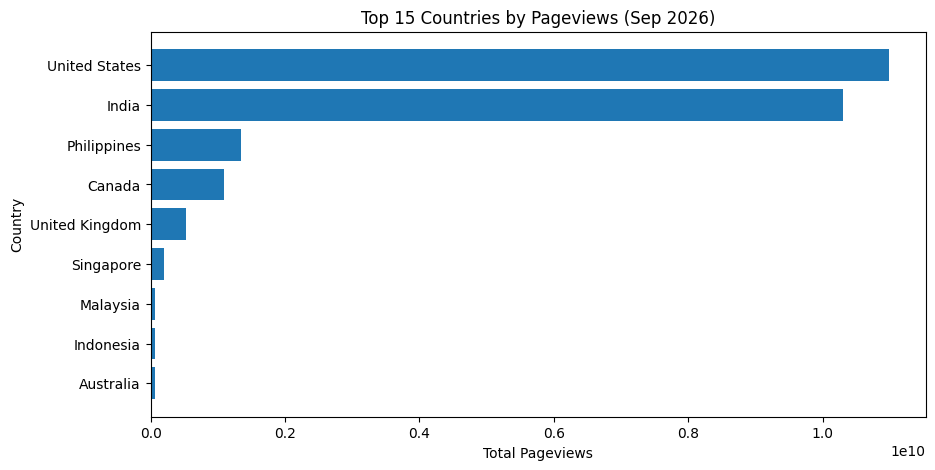

In [50]:
country_views = df_september.groupby('country')['page_views'].sum().reset_index()
country_views = country_views.sort_values(by='page_views', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(country_views['country'].head(15), country_views['page_views'].head(15))
plt.xlabel('Total Pageviews')
plt.ylabel('Country')
plt.title('Top 15 Countries by Pageviews (Sep 2026)')
plt.gca().invert_yaxis()  # Put top country at the top
plt.show()

### Create Bar Chart to view by Dramas

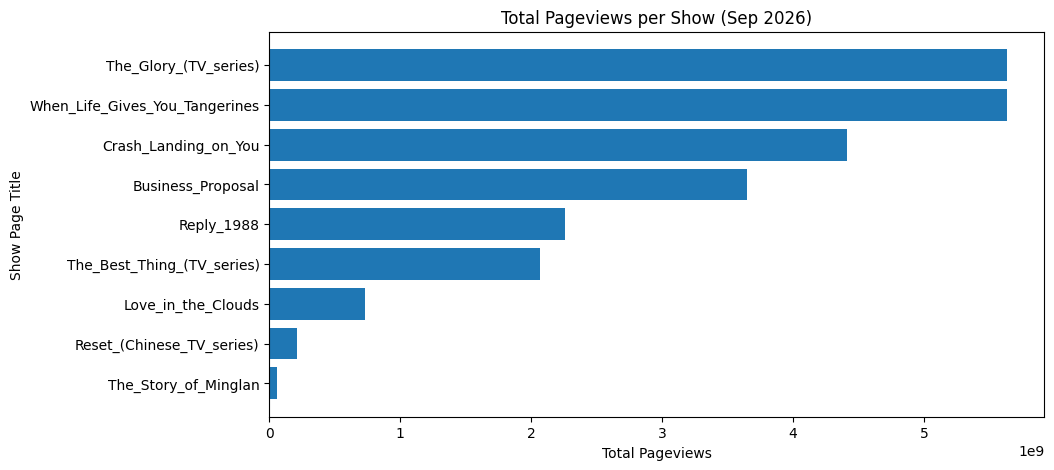

In [51]:
show_views = df_september.groupby('page_title')['page_views'].sum().reset_index()
show_views = show_views.sort_values(by='page_views', ascending=False)

plt.figure(figsize=(10, 5))
plt.barh(show_views['page_title'], show_views['page_views'])
plt.xlabel('Total Pageviews')
plt.ylabel('Show Page Title')
plt.title('Total Pageviews per Show (Sep 2026)')
plt.gca().invert_yaxis()
plt.show()

### Compare MyDramaList Rating vs Pageviews

In [52]:
df_shows_info = pd.DataFrame(shows_data)
summary_df = pd.merge(show_views, df_shows_info, on='page_title')
summary_df = summary_df[['title', 'rating', 'page_views']].sort_values(by='page_views', ascending=False)

print("\nSummary Table: ")
print(summary_df)


Summary Table: 
                            title  rating  page_views
0                       The Glory     8.9  5637429888
1  When Life Gives You Tangerines     9.3  5629969425
2            Crash Landing on You     9.0  4414179960
3               Business Proposal     8.6  3649890132
4                      Reply 1988     9.0  2254830828
5                  The Best Thing     8.7  2065756082
6              Love in the Clouds     8.8   731459511
7                           Reset     9.0   209584815
8            The Story of Minglan     8.7    55685530
